In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.signal import find_peaks, savgol_filter
from scipy.optimize import curve_fit, minimize_scalar

In [2]:
CAL_FILE = "data_monochromator_calibration_300V.csv"
FL_FILE  = "data_fluorescence_spectrum_600V.csv"

DRUM_LC_CM = 0.01
GALV_LC_100nA = 0.1

U_DRUM = DRUM_LC_CM / 2.0
U_GALV = GALV_LC_100nA / 2.0

In [3]:
HG_WAVELENGTH_NM = np.array([
    404.7,   # Deep Violet
    407.8,   # Violet
    435.8,   # Indigo - Violet
    491.6,   # Blue - Green
    546.1,   # Green (yellowish)
    577.0,   # Yellow - Orange
    579.1,   # Yellow - Orange
    623.4,   # Red
    690.8,   # Red
])

In [4]:
HG_RELATIVE_INTENSITY = np.array([
    1800,
    150,
    4000,
    80,
    1100,
    240,
    280,
    np.nan,    # table has no relative intensity
    np.nan,    # table has no relative intensity
])

In [5]:
HG_COLOUR = [
    "Violet (deep)",
    "Violet",
    "Indigo-violet",
    "Blue-green (deep-green)",
    "Green (yellowish)",
    "Yellow-orange",
    "Yellow-orange",
    "Red",
    "Red",
]

In [6]:
HG_TABLE = pd.DataFrame({
    "wavelength_nm": HG_WAVELENGTH_NM,
    "colour": HG_COLOUR,
    "relative_intensity": HG_RELATIVE_INTENSITY,
})

print("\n================ MERCURY REFERENCE TABLE ================")
print(HG_TABLE.to_string(index=False))


================ MERCURY REFERENCE TABLE ================
 wavelength_nm                  colour  relative_intensity
         404.7           Violet (deep)              1800.0
         407.8                  Violet               150.0
         435.8           Indigo-violet              4000.0
         491.6 Blue-green (deep-green)                80.0
         546.1       Green (yellowish)              1100.0
         577.0           Yellow-orange               240.0
         579.1           Yellow-orange               280.0
         623.4                     Red                 NaN
         690.8                     Red                 NaN


In [7]:
def read_scan(path):
    df = pd.read_csv(path)

    if df.shape[1] < 2:
        raise ValueError(f"{path} does not contain two columns.")

    d = pd.to_numeric(df.iloc[:, 0], errors="coerce").to_numpy()
    I = pd.to_numeric(df.iloc[:, 1], errors="coerce").to_numpy()

    mask = np.isfinite(d) & np.isfinite(I)
    d, I = d[mask], I[mask]

    idx = np.argsort(d)

    return d[idx], I[idx]


hg_D, hg_I = read_scan(CAL_FILE)
fl_D, fl_I = read_scan(FL_FILE)

print("\n================ DATA SUMMARY ================")
print(f"Hg scan measurements:          {len(hg_D)}")
print(f"Fluorescence measurements:     {len(fl_D)}")
print(f"Drum least count:              {DRUM_LC_CM:.3f} cm")
print(f"Drum standard uncertainty:     {U_DRUM:.5f} cm")
print(f"Galvanometer least count:      {GALV_LC_100nA:.3f} × 100 nA")
print(f"Galvanometer standard error:   {U_GALV:.5f} × 100 nA")



================ DATA SUMMARY ================
Hg scan measurements:          74
Fluorescence measurements:     84
Drum least count:              0.010 cm
Drum standard uncertainty:     0.00500 cm
Galvanometer least count:      0.100 × 100 nA
Galvanometer standard error:   0.05000 × 100 nA


In [8]:
# 3. GENERIC PEAK DETECTION

def smooth(y):
    """Optional visual helper only; never use it for peak amplitudes."""
    n = len(y)
    if n < 7:
        return y.copy()
    window = min(5, n if n % 2 else n - 1)
    if window < 5:
        return y.copy()
    return savgol_filter(y, window_length=window, polyorder=2)


def detect_candidates(D, I, prominence=2.0, use_smoothing=False):
    """Find candidate peaks directly from the measured data by default.

    Smoothing is OFF by default because these scans are sparsely sampled and
    narrow peaks can be attenuated or shifted by smoothing. The measured
    intensities must remain the source of truth for Hg line identification.
    """
    signal = smooth(I) if use_smoothing else I

    idx, props = find_peaks(
        signal,
        prominence=prominence,
        distance=2,
    )

    return D[idx], I[idx], signal, idx, props


In [9]:
# 4. PLOT MERCURY RAW DATA

hg_candidate_D, hg_candidate_I, hg_smooth, hg_peak_idx, hg_props = \
    detect_candidates(hg_D, hg_I, prominence=5.0, use_smoothing=False)


In [10]:
# Inspections
print(hg_candidate_D)
print(type(hg_candidate_D))

print(hg_candidate_I)
print(type(hg_candidate_I))

[13.19 13.51 13.6  15.38 16.29 17.9 ]
<class 'numpy.ndarray'>
[111.2 187.9  79.4 137.3  52.9  15.8]
<class 'numpy.ndarray'>


In [11]:
# Manual Corrections
hg_candidate_D = np.insert(hg_candidate_D, 3, 14.25)
hg_candidate_D = np.insert(hg_candidate_D, 0, 12.87)

hg_candidate_I = np.insert(hg_candidate_I, 3, 12.6)
hg_candidate_I = np.insert(hg_candidate_I, 0, 14.1)

In [12]:
# Inspections post manual edits
print(hg_candidate_D, len(hg_candidate_D))
print(hg_candidate_I, len(hg_candidate_I))

[12.87 13.19 13.51 13.6  14.25 15.38 16.29 17.9 ] 8
[ 14.1 111.2 187.9  79.4  12.6 137.3  52.9  15.8] 8


In [13]:
# Correction 2: Manual Recalib
hg_candidate_D = np.array([13.19, 13.51, 14.25, 15.38, 16.29, 17.9])
hg_candidate_I = np.array([111.2, 187.9, 12.6, 137.3, 52.9, 15.8])

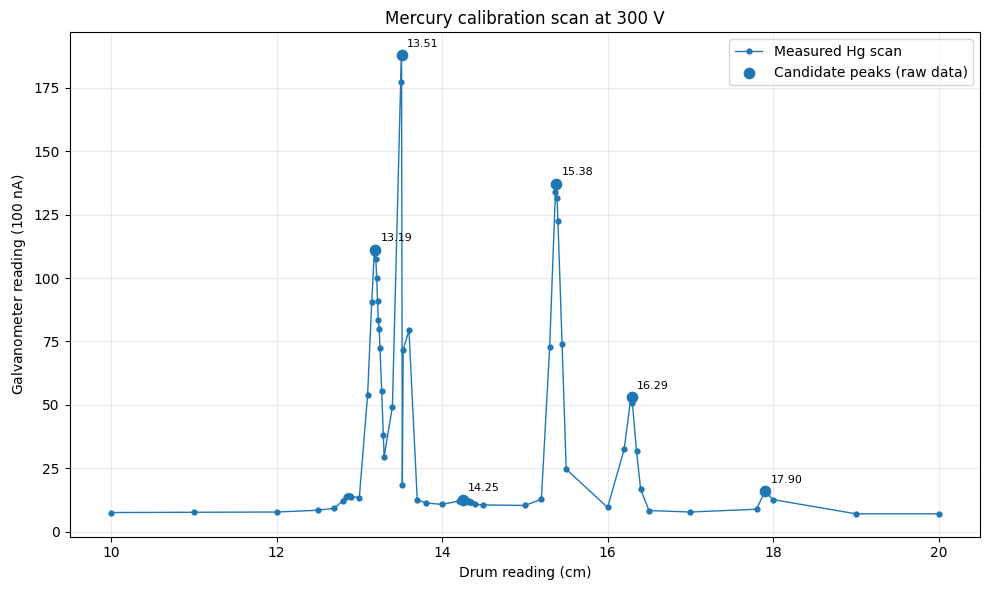


NOTE: Peak detection and calibration use the ORIGINAL measured intensities.
      No smoothing is applied to the Hg scan, because smoothing can
      attenuate or shift narrow peaks, especially with sparse sampling.

================ CANDIDATE Hg PEAKS ================
D = 13.1900 cm, I = 111.20 × 100 nA
D = 13.5100 cm, I = 187.90 × 100 nA
D = 14.2500 cm, I = 12.60 × 100 nA
D = 15.3800 cm, I = 137.30 × 100 nA
D = 16.2900 cm, I = 52.90 × 100 nA
D = 17.9000 cm, I = 15.80 × 100 nA


In [14]:
plt.figure(figsize=(10, 6))
plt.plot(hg_D, hg_I, "o-", ms=3.5, lw=1.0, label="Measured Hg scan")
# Do NOT smooth the calibration scan for plotting: smoothing can suppress
# narrow Hg peaks (as happens near D≈13.51 cm).

plt.scatter(
    hg_candidate_D,
    hg_candidate_I,
    s=55,
    zorder=5,
    label="Candidate peaks (raw data)"
)

for d, I in zip(hg_candidate_D, hg_candidate_I):
    plt.annotate(
        f"{d:.2f}",
        (d, I),
        xytext=(4, 6),
        textcoords="offset points",
        fontsize=8
    )

plt.xlabel("Drum reading (cm)")
plt.ylabel(r"Galvanometer reading ($100$ nA)")
plt.title("Mercury calibration scan at 300 V")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.savefig("01_Hg_intensity_vs_drum.png", dpi=300)
plt.show()

print("\nNOTE: Peak detection and calibration use the ORIGINAL measured intensities.")
print("      No smoothing is applied to the Hg scan, because smoothing can")
print("      attenuate or shift narrow peaks, especially with sparse sampling.")

print("\n================ CANDIDATE Hg PEAKS ================")
for d, I in zip(hg_candidate_D, hg_candidate_I):
    print(f"D = {d:.4f} cm, I = {I:.2f} × 100 nA")


In [15]:
CALIBRATION_POINTS = [
        (12.87, 623.4, "HG 623.4"),
        (13.19, 579.1, "HG 579.1"),
        (13.51, 577.0, "HG 577"),
        (13.6, 546.1, "HG 546.1"),
        (14.25, 491.6, "HG 491.6"),
        (15.38, 435.8, "HG 435.8"),
        (16.29, 407.8, "HG 407.8"),
        (17.29, 404.7, "HG 404.7"),]


---- LOOCV trace (decaying exponential) ----
    [exp] left out i=0 (D=12.870 cm, lambda=623.4 nm): predicted= 633.856 nm, LOO residual=  -10.456 nm
    [exp] left out i=1 (D=13.190 cm, lambda=579.1 nm): predicted= 591.135 nm, LOO residual=  -12.035 nm
    [exp] left out i=2 (D=13.510 cm, lambda=577.0 nm): predicted= 548.949 nm, LOO residual=  +28.051 nm
    [exp] left out i=3 (D=13.600 cm, lambda=546.1 nm): predicted= 546.989 nm, LOO residual=   -0.889 nm
    [exp] left out i=4 (D=14.250 cm, lambda=491.6 nm): predicted= 499.296 nm, LOO residual=   -7.696 nm
    [exp] left out i=5 (D=15.380 cm, lambda=435.8 nm): predicted= 442.950 nm, LOO residual=   -7.150 nm
    [exp] left out i=6 (D=16.290 cm, lambda=407.8 nm): predicted= 417.501 nm, LOO residual=   -9.701 nm
    [exp] left out i=7 (D=17.290 cm, lambda=404.7 nm): predicted= 381.361 nm, LOO residual=  +23.339 nm
    -> LOOCV RMSE = sqrt(mean(residual^2)) = 14.9624 nm
  Fitted parameters:  lambda(D) = C + A * exp(-(D - D0)/tau)
    D

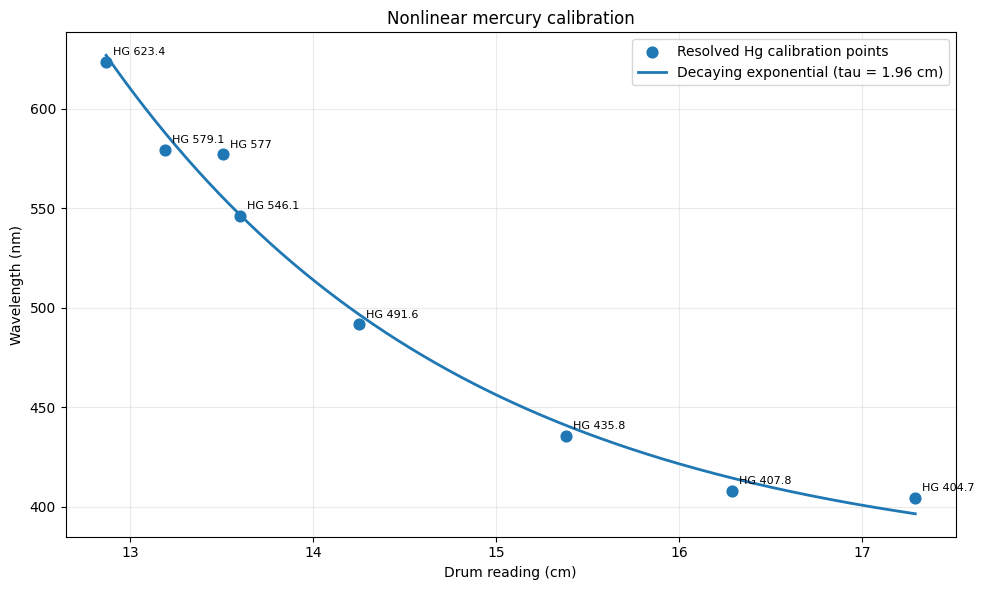

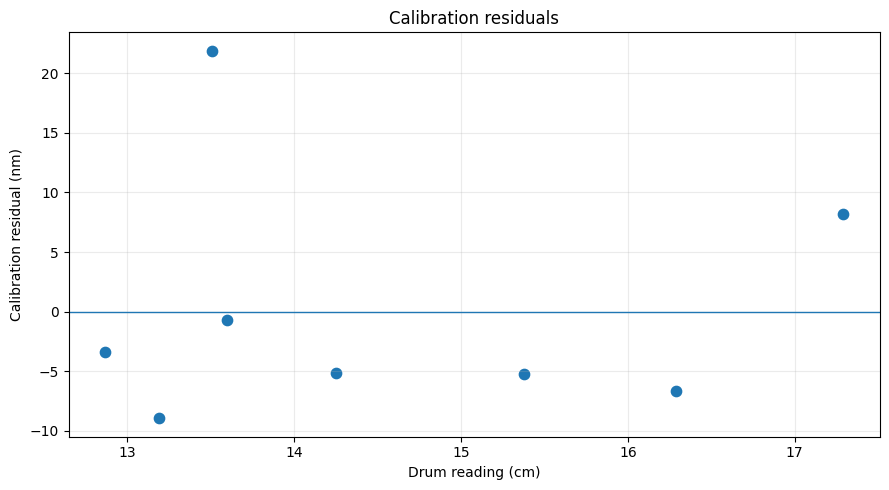

In [16]:
# ==============================================================
# 6. NONLINEAR CALIBRATION  (decaying-exponential model)
# ==============================================================
#
# Model:   lambda(D) = C + A * exp(-(D - D0) / tau),   tau > 0,  D0 = min(D)
#
#   * C    : asymptotic wavelength as D -> infinity
#   * A    : signed amplitude (A > 0 -> lambda decreasing in D, convex;
#                              A < 0 -> lambda increasing in D, concave)
#   * tau  : decay constant, in drum-reading units (cm)
#
# A and C enter linearly, so for a fixed tau they are found exactly by linear
# least squares. Only tau needs a 1-D search (variable projection). This avoids
# the initial-guess / non-convergence problems of a generic curve_fit call and
# makes the leave-one-out refits fast and reliable.
#
# This fitted curve (and its analytic derivative) is the ONLY drum -> wavelength
# mapping used anywhere in this notebook: wavelength conversion, peak positions,
# uncertainty propagation and the error budget all go through `calib` below.

N_PARAMS_EXP = 3  # A, tau, C


class ExpDecayCalibration:
    """Calibration curve lambda(D) = C + A*exp(-(D-D0)/tau).

    Calling the object converts drum reading(s) in cm to wavelength in nm.
    .derivative(D) returns the analytic slope d(lambda)/dD in nm/cm, which is
    what the uncertainty propagation downstream uses.
    """

    def __init__(self, A, tau, C, D0):
        self.A = float(A)
        self.tau = float(tau)
        self.C = float(C)
        self.D0 = float(D0)

    def __call__(self, D):
        D = np.asarray(D, dtype=float)
        return self.C + self.A * np.exp(-(D - self.D0) / self.tau)

    def derivative(self, D):
        """Analytic d(lambda)/dD = -(A/tau) * exp(-(D - D0)/tau)."""
        D = np.asarray(D, dtype=float)
        return -(self.A / self.tau) * np.exp(-(D - self.D0) / self.tau)


def fit_exp_decay(x, y):
    """Least-squares fit of y = C + A*exp(-(x - x0)/tau) with tau > 0."""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    x0 = x.min()
    span = x.max() - x.min()

    def solve(log_tau):
        tau = np.exp(log_tau)
        basis = np.column_stack([np.exp(-(x - x0) / tau), np.ones_like(x)])
        (A, C), *_ = np.linalg.lstsq(basis, y, rcond=None)
        sse = float(np.sum((y - basis @ np.array([A, C])) ** 2))
        return sse, A, C

    # Coarse grid over tau (log-spaced) to land in the right basin, then refine.
    lo, hi = np.log(0.05 * span), np.log(50.0 * span)
    grid = np.linspace(lo, hi, 200)
    sse_grid = np.array([solve(g)[0] for g in grid])
    k = int(np.argmin(sse_grid))
    a, b = grid[max(k - 1, 0)], grid[min(k + 1, len(grid) - 1)]
    res = minimize_scalar(
        lambda g: solve(g)[0], bounds=(a, b),
        method="bounded", options={"xatol": 1e-10},
    )
    _, A, C = solve(res.x)
    return ExpDecayCalibration(A, np.exp(res.x), C, x0)


def loo_rmse(x, y, fit_fn, n_params, label="model", verbose=False):
    """Leave-one-out RMSE for an arbitrary fitting function.

    ERROR-ANALYSIS NOTE:
    Each left-out point gives one leave-one-out residual
        e_i = y_i - f_{-i}(x_i)
    where f_{-i} is fit on all points EXCEPT i (including a fresh search for
    tau in the exponential case). Averaging the squares of these n residuals
    makes rmse_cv a much more honest estimate of out-of-sample calibration
    error than the training RMSE (which reuses every point in its own fit).
    """
    n = len(x)

    if n <= n_params:
        return np.inf, []

    errors = []

    for i in range(n):
        mask = np.ones(n, dtype=bool)
        mask[i] = False

        model = fit_fn(x[mask], y[mask])
        prediction = float(model(x[i]))

        e = y[i] - prediction
        errors.append(e)

        if verbose:
            print(
                f"    [{label}] left out i={i:d} "
                f"(D={x[i]:.3f} cm, lambda={y[i]:.1f} nm): "
                f"predicted={prediction:8.3f} nm, "
                f"LOO residual={e:+9.3f} nm"
            )

    rmse = float(np.sqrt(np.mean(np.square(errors))))
    return rmse, errors


def fit_exp_calibration(Dcal, Lcal):
    """Fit the decaying-exponential calibration and report its LOOCV RMSE."""
    print("\n---- LOOCV trace (decaying exponential) ----")
    rmse_cv, loo_errors = loo_rmse(
        Dcal, Lcal, fit_exp_decay, N_PARAMS_EXP, label="exp", verbose=True
    )
    print(f"    -> LOOCV RMSE = sqrt(mean(residual^2)) = {rmse_cv:.4f} nm")

    model = fit_exp_decay(Dcal, Lcal)
    span = Dcal.max() - Dcal.min()

    print("  Fitted parameters:  lambda(D) = C + A * exp(-(D - D0)/tau)")
    print(f"    D0  = {model.D0:+.6f} cm (fixed = min drum reading)")
    print(f"    A   = {model.A:+.6f} nm")
    print(f"    tau = {model.tau:+.6f} cm  (tau/span = {model.tau / span:.2f})")
    print(f"    C   = {model.C:+.6f} nm")

    if model.tau / span > 40:
        print("  WARNING: tau is at the upper search bound -- the data are nearly\n"
              "           linear in D and A, C are strongly collinear.")
    if model.tau / span < 0.06:
        print("  WARNING: tau is at the lower search bound -- the curve is much\n"
              "           sharper than the calibration spacing can resolve.")

    return model, rmse_cv, loo_errors


Dcal = np.array([p[0] for p in CALIBRATION_POINTS], dtype=float)
Lcal = np.array([p[1] for p in CALIBRATION_POINTS], dtype=float)

# Sort in increasing drum reading.
idx = np.argsort(Dcal)
Dcal = Dcal[idx]
Lcal = Lcal[idx]

# A prism may produce either direction of monotonicity depending on how the
# drum scale is defined. Therefore do NOT hard-code positive d(lambda)/d(D).
dL = np.diff(Lcal)

if not (np.all(dL > 0) or np.all(dL < 0)):
    raise ValueError(
        "Calibration points are not monotonic in wavelength. "
        "Check Hg assignments."
    )

calib, rmse_cv, loo_errors = fit_exp_calibration(Dcal, Lcal)
exp_params = dict(A=calib.A, tau=calib.tau, C=calib.C, D0=calib.D0)

print("\n---- Why LOOCV RMSE (not training RMSE) is used downstream ----")
print(
    "Training RMSE reuses every calibration point in its own fit, so it is\n"
    "an optimistic (biased-low) estimate of how well the curve predicts a\n"
    "wavelength it has never seen. LOOCV RMSE refits the model n times,\n"
    "each time holding one point out, so every LOO residual is a genuine\n"
    "out-of-sample prediction error. sigma_cal_nm is therefore set to the\n"
    "LOOCV RMSE of the exponential model later in this notebook, not the\n"
    "training RMSE."
)

Lpred = calib(Dcal)
residuals = Lcal - Lpred

rmse_train = np.sqrt(np.mean(residuals**2))

print("\n================ NONLINEAR CALIBRATION ================")
print("Model: decaying exponential  lambda = C + A*exp(-(D - D0)/tau)")
print(f"Training RMSE:              {rmse_train:.4f} nm   (optimistic; NOT used as sigma_cal)")
print(f"LOOCV RMSE:                 {rmse_cv:.4f} nm   (used as sigma_cal_nm downstream)")
print(
    f"\nRatio LOOCV/training = {rmse_cv / rmse_train:.2f}x -- the gap between these two\n"
    "numbers IS the cost of having only "
    f"{len(Dcal)} calibration points spread unevenly across the scan range;\n"
    "it is the single largest term in the final error budget (see Section\n"
    "\'ERROR BUDGET\' at the end of the notebook)."
)

print("\nCalibration points:")
for D, L, point in zip(Dcal, Lcal, sorted(CALIBRATION_POINTS)):
    print(f"{point[2]:>10s}: D={D:.3f} cm -> {L:.1f} nm")

print("\nCalibration residuals:")
for D, L, r in zip(Dcal, Lcal, residuals):
    print(
        f"D={D:8.3f} cm, "
        f"lambda={L:7.2f} nm, "
        f"residual={r:+8.3f} nm"
    )


# ==============================================================
# 7. CALIBRATION PLOT + RESIDUALS
# ==============================================================

Dplot = np.linspace(Dcal.min(), Dcal.max(), 1000)

plt.figure(figsize=(10, 6))
plt.scatter(
    Dcal,
    Lcal,
    s=60,
    zorder=5,
    label="Resolved Hg calibration points"
)
plt.plot(
    Dplot,
    calib(Dplot),
    lw=2.0,
    label=(
        f"Decaying exponential "
        f"(tau = {calib.tau:.2f} cm)"
    )
)
for D, L, label in CALIBRATION_POINTS:
    plt.annotate(
        label.replace("Hg ", ""),
        (D, L),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

plt.xlabel("Drum reading (cm)")
plt.ylabel("Wavelength (nm)")
plt.title("Nonlinear mercury calibration")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.savefig("02_Hg_nonlinear_calibration.png", dpi=300)
plt.show()

plt.figure(figsize=(9, 5))
plt.axhline(0, lw=1)
plt.scatter(Dcal, residuals, s=55)
plt.xlabel("Drum reading (cm)")
plt.ylabel("Calibration residual (nm)")
plt.title("Calibration residuals")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig("03_Hg_calibration_residuals.png", dpi=300)
plt.show()


25 fluorescence points lie outside the Hg calibration range and will not be assigned wavelengths.

---- Calibration uncertainty adopted for propagation ----
sigma_cal_nm = LOOCV RMSE of the decaying-exponential fit = 14.9624 nm
This single number is treated as a constant, point-independent
contribution to every wavelength uncertainty computed below -- it
does NOT vary with drum reading, unlike the drum-derivative term.

================ WAVELENGTH-UNCERTAINTY PROPAGATION TRACE ================
For every retained fluorescence point:
  u_lambda,drum = |dlambda/dD (exponential-fit slope)| * U_DRUM
  u_lambda      = sqrt( u_lambda,drum^2 + sigma_cal_nm^2 )

U_DRUM = 0.00500 cm,  sigma_cal_nm = 14.9624 nm

   D (cm)   dλ/dD (nm/cm)   u_λ,drum (nm)   u_λ,total (nm)  dominant term
  13.0000       -122.8965         0.61448          14.9750    calibration
  13.5000        -95.2080         0.47604          14.9700    calibration
  13.5500        -92.8083         0.46404          14.9696    cali

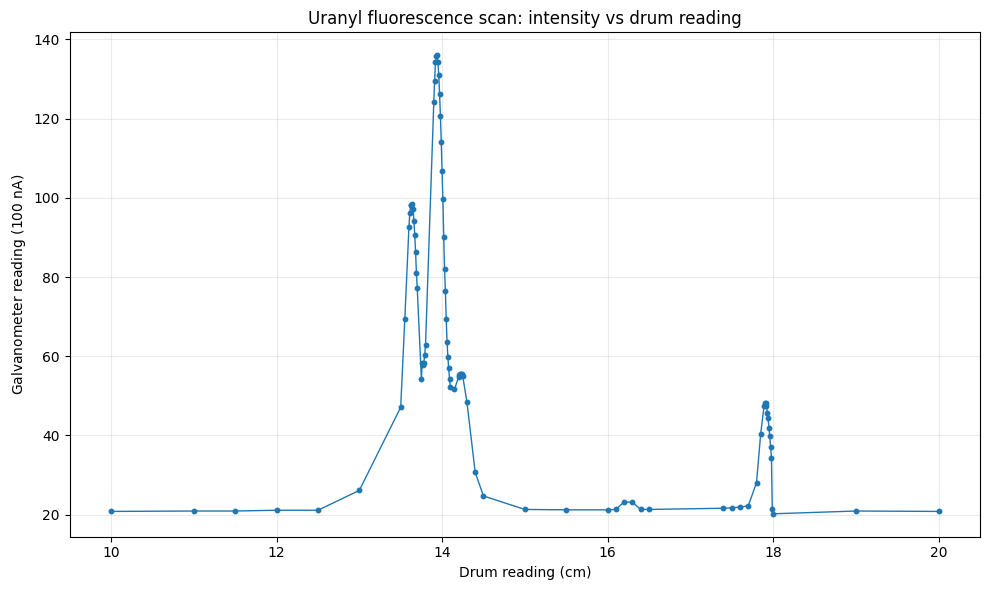

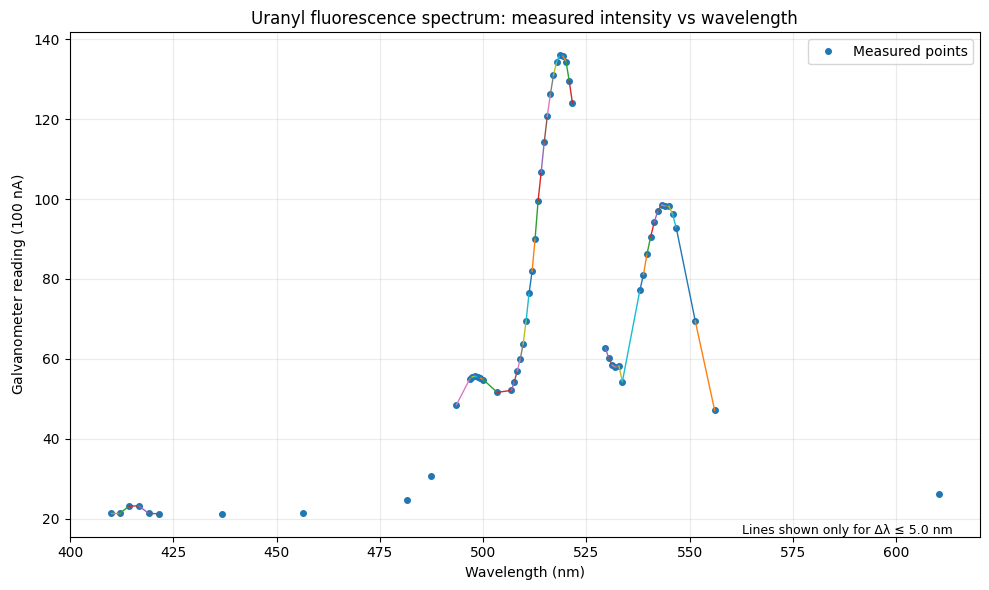


================ WAVELENGTH SAMPLING GAPS ================
421.62 -> 436.76 nm (Δλ = 15.13 nm): no line is drawn across this gap.
436.76 -> 456.29 nm (Δλ = 19.53 nm): no line is drawn across this gap.
456.29 -> 481.51 nm (Δλ = 25.21 nm): no line is drawn across this gap.
481.51 -> 487.37 nm (Δλ = 5.86 nm): no line is drawn across this gap.
487.37 -> 493.54 nm (Δλ = 6.17 nm): no line is drawn across this gap.
521.62 -> 529.59 nm (Δλ = 7.96 nm): no line is drawn across this gap.
556.07 -> 610.30 nm (Δλ = 54.23 nm): no line is drawn across this gap.

================ FLUORESCENCE PEAK CANDIDATES ================
D= 13.6400 cm, lambda≈  543.204 nm, I=   98.50 × 100 nA
D= 13.9400 cm, lambda≈  518.549 nm, I=  136.00 × 100 nA
D= 14.2300 cm, lambda≈  498.048 nm, I=   55.60 × 100 nA


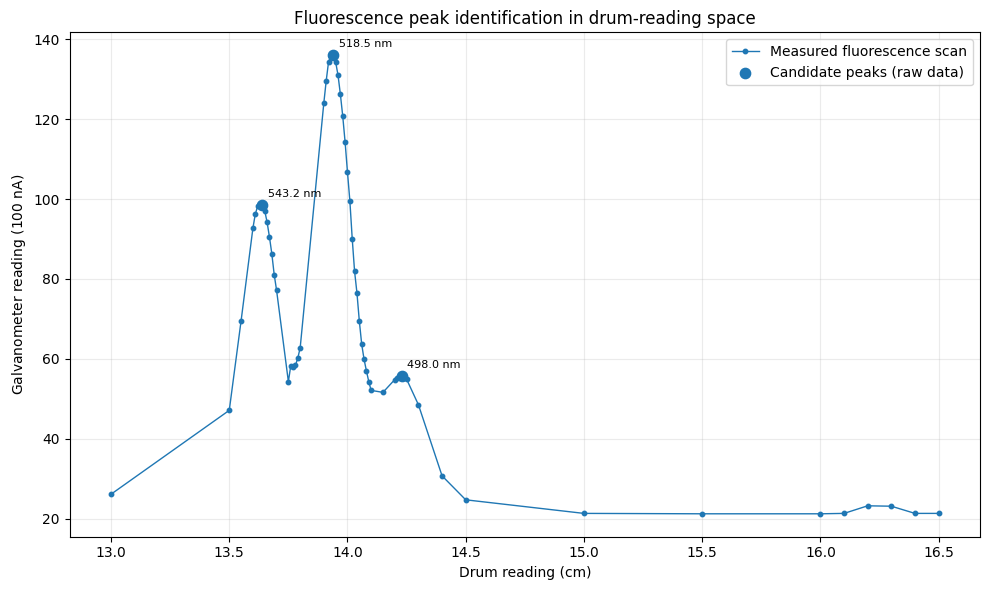

In [17]:

# ==============================================================
# 8. DRUM -> WAVELENGTH CONVERSION
# ==============================================================

"""
The drum -> wavelength conversion of the unknown spectrum uses the fitted
decaying-exponential calibration

    lambda(D) = C + A*exp(-(D - D0)/tau)

from Section 6. The same fitted curve, and its analytic derivative, are used
for every downstream calculation.

Most importantly:
    DO NOT extrapolate.
The calibration uncertainty (LOOCV RMSE) is only characterised inside the
range of the Hg calibration points, so points outside that range are
reported separately and are not assigned wavelengths.
"""

fl_in = (
    (fl_D >= Dcal.min()) &
    (fl_D <= Dcal.max())
)

fl_D_cal = fl_D[fl_in]
fl_I_cal = fl_I[fl_in]

fl_D_outside = fl_D[~fl_in]
fl_I_outside = fl_I[~fl_in]

if len(fl_D_outside):
    print("\nWARNING:")
    print(
        f"{len(fl_D_outside)} fluorescence points lie outside the "
        "Hg calibration range and will not be assigned wavelengths."
    )

fl_lambda = np.asarray(calib(fl_D_cal), dtype=float)

# Approximate empirical calibration uncertainty:
# use the LOOCV error of the exponential calibration as a practical
# calibration uncertainty.
sigma_cal_nm = rmse_cv

print("\n---- Calibration uncertainty adopted for propagation ----")
print(
    f"sigma_cal_nm = LOOCV RMSE of the decaying-exponential fit "
    f"= {sigma_cal_nm:.4f} nm"
)
print(
    "This single number is treated as a constant, point-independent\n"
    "contribution to every wavelength uncertainty computed below -- it\n"
    "does NOT vary with drum reading, unlike the drum-derivative term."
)


# ==============================================================
# 9. PROPAGATE DRUM UNCERTAINTY INTO WAVELENGTH
# ==============================================================

# Analytic slope of the fitted exponential: -(A/tau) * exp(-(D - D0)/tau)
dlambda_dD = np.asarray(calib.derivative(fl_D_cal), dtype=float)

u_lambda_from_drum = np.abs(dlambda_dD) * U_DRUM

u_lambda_total = np.sqrt(
    u_lambda_from_drum**2 +
    sigma_cal_nm**2
)

print("\n================ WAVELENGTH-UNCERTAINTY PROPAGATION TRACE ================")
print(
    "For every retained fluorescence point:\n"
    "  u_lambda,drum = |dlambda/dD (exponential-fit slope)| * U_DRUM\n"
    "  u_lambda      = sqrt( u_lambda,drum^2 + sigma_cal_nm^2 )\n"
)
print(f"U_DRUM = {U_DRUM:.5f} cm,  sigma_cal_nm = {sigma_cal_nm:.4f} nm\n")
print(
    f"{'D (cm)':>9s} {'dλ/dD (nm/cm)':>15s} {'u_λ,drum (nm)':>15s} "
    f"{'u_λ,total (nm)':>16s} {'dominant term':>14s}"
)
_n_show = min(10, len(fl_D_cal))
for _D, _s, _ud, _ut in zip(
    fl_D_cal[:_n_show], dlambda_dD[:_n_show],
    u_lambda_from_drum[:_n_show], u_lambda_total[:_n_show]
):
    dominant = "calibration" if sigma_cal_nm >= _ud else "drum reading"
    print(f"{_D:9.4f} {_s:15.4f} {_ud:15.5f} {_ut:16.4f} {dominant:>14s}")
if len(fl_D_cal) > _n_show:
    print(f"... ({len(fl_D_cal) - _n_show} more points, same pattern)")

print(
    f"\nAcross all {len(fl_D_cal)} retained points: "
    f"u_lambda,drum ranges {u_lambda_from_drum.min():.4f}-{u_lambda_from_drum.max():.4f} nm, "
    f"while sigma_cal_nm is a constant {sigma_cal_nm:.4f} nm."
)
_ratio_max = u_lambda_from_drum.max() / sigma_cal_nm
if _ratio_max < 0.1:
    print(
        "-> The calibration term dominates u_lambda,total everywhere in this scan\n"
        f"   (largest u_lambda,drum is {100 * _ratio_max:.1f}% of sigma_cal_nm), so the\n"
        "   drum-derivative term only matters at the 3rd-4th significant figure."
    )
else:
    print(
        "-> The drum-derivative term is NOT negligible everywhere: the largest\n"
        f"   u_lambda,drum is {100 * _ratio_max:.1f}% of sigma_cal_nm."
    )


# ==============================================================
# 10. FLUORESCENCE: RAW DRUM PLOT
# ==============================================================

plt.figure(figsize=(10, 6))
plt.plot(fl_D, fl_I, "o-", ms=3.2, lw=1.0)
plt.xlabel("Drum reading (cm)")
plt.ylabel(r"Galvanometer reading ($100$ nA)")
plt.title("Uranyl fluorescence scan: intensity vs drum reading")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig("04_fluorescence_intensity_vs_drum.png", dpi=300)
plt.show()


# ==============================================================
# 11. FLUORESCENCE: WAVELENGTH PLOT
# ==============================================================

order = np.argsort(fl_lambda)

lam_sorted = fl_lambda[order]
I_sorted = fl_I_cal[order]
u_lam_sorted = u_lambda_total[order]

# Do not connect widely separated wavelength measurements.
# Such straight lines would be interpolation, not measured spectral structure.
wavelength_gap_threshold_nm = 5.0

plt.figure(figsize=(10, 6))
plt.plot(
    lam_sorted,
    I_sorted,
    linestyle="None",
    marker="o",
    markersize=4,
    label="Measured points",
)

# Connect points only when they are densely sampled in wavelength.
for i in range(len(lam_sorted) - 1):
    gap = lam_sorted[i + 1] - lam_sorted[i]

    if gap <= wavelength_gap_threshold_nm:
        plt.plot(
            [lam_sorted[i], lam_sorted[i + 1]],
            [I_sorted[i], I_sorted[i + 1]],
            linewidth=1.0,
        )

plt.xlabel("Wavelength (nm)")
plt.ylabel(r"Galvanometer reading ($100$ nA)")
plt.title("Uranyl fluorescence spectrum: measured intensity vs wavelength")
plt.grid(alpha=0.25)
plt.legend()
plt.text(
    0.97,
    0.000,
    f"Lines shown only for Δλ ≤ {wavelength_gap_threshold_nm:.1f} nm",
    transform=plt.gca().transAxes,
    ha="right",
    va="bottom",
    fontsize=9,
)
plt.tight_layout()
plt.savefig(
    "05_fluorescence_intensity_vs_wavelength_no_artificial_gaps.png",
    dpi=300,
)
plt.show()

large_gap_idx = np.where(
    np.diff(lam_sorted) > wavelength_gap_threshold_nm
)[0]

print("\n================ WAVELENGTH SAMPLING GAPS ================")
if len(large_gap_idx) == 0:
    print("No wavelength gaps larger than the threshold.")
else:
    for i in large_gap_idx:
        print(
            f"{lam_sorted[i]:.2f} -> {lam_sorted[i+1]:.2f} nm "
            f"(Δλ = {lam_sorted[i+1] - lam_sorted[i]:.2f} nm): "
            "no line is drawn across this gap."
        )


# ==============================================================
# 12. AUTOMATIC FLUORESCENCE PEAK CANDIDATES
# ==============================================================

# IMPORTANT:
# Peak identification is performed directly in DRUM space using the RAW
# measured fluorescence points. No global smoothing and no wavelength-space
# interpolation are used to find peaks.
#
# Only after a drum-space peak has been identified do we convert its position
# to wavelength with the calibration function.

candidate_signal = fl_I_cal

candidate_idx, candidate_props = find_peaks(
    candidate_signal,
    prominence=3.0,
    distance=2,
)

candidate_D = fl_D_cal[candidate_idx]
candidate_I = fl_I_cal[candidate_idx]
candidate_lambda = np.asarray(calib(candidate_D), dtype=float)

print("\n================ FLUORESCENCE PEAK CANDIDATES ================")
for D, I, L in zip(candidate_D, candidate_I, candidate_lambda):
    print(
        f"D={D:8.4f} cm, "
        f"lambda≈{L:9.3f} nm, "
        f"I={I:8.2f} × 100 nA"
    )

plt.figure(figsize=(10, 6))
plt.plot(
    fl_D_cal,
    fl_I_cal,
    "o-",
    ms=3.2,
    lw=1.0,
    label="Measured fluorescence scan",
)
plt.scatter(
    candidate_D,
    candidate_I,
    s=55,
    zorder=5,
    label="Candidate peaks (raw data)",
)

for D, I, L in zip(candidate_D, candidate_I, candidate_lambda):
    plt.annotate(
        f"{L:.1f} nm",
        (D, I),
        xytext=(4, 6),
        textcoords="offset points",
        fontsize=8,
    )

plt.xlabel("Drum reading (cm)")
plt.ylabel(r"Galvanometer reading ($100$ nA)")
plt.title("Fluorescence peak identification in drum-reading space")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.savefig(
    "06_candidate_fluorescence_peaks_in_drum_space.png",
    dpi=300,
)
plt.show()

In [18]:
FLUORESCENCE_BAND_DRUMS = [
    13.64, 13.94, 14.23
]


    -- local quadratic fit trace around D_guess=13.6400 cm --
       points used: n=5, window=+/-0.025 cm, x0(mean)=13.64000 cm
       fitted (a,b,c) = (-5428.5713, -92.0000, 98.3457)
       pcov(a,b,c) =
[[ 1.0796e+06 -3.7932e-03 -2.1592e+02]
 [-3.7932e-03  1.5114e+02  7.5864e-07]
 [-2.1592e+02  7.5864e-07  7.3412e-02]]
       u_peak = -b/(2a) = -0.008474 cm  ->  D_peak = x0+u_peak = 13.631526 cm
       gradient dD_peak/d(a,b,c) = (-0.00000, 0.00009, 0.00000)
       Var(D_peak) = grad . pcov . grad^T = 3.913e-06 cm^2
       u_D_fit = sqrt(Var) = 0.001978 cm
    band @ D_guess=13.6400 cm  -- full uncertainty chain --
       D_peak=13.63153 cm, exponential-fit slope dλ/dD=-89.0246 nm/cm
       u_D_total  = sqrt(U_DRUM^2 + u_D_fit^2) = sqrt(0.00500^2 + 0.00198^2) = 0.00538 cm
       u_lambda,reading = |slope| * u_D_total = 89.0246 * 0.00538 = 0.47869 nm
       u_lambda   = sqrt(u_lambda,reading^2 + sigma_cal_nm^2) = sqrt(0.47869^2 + 14.9624^2) = 14.9700 nm
       lambda_peak = 543.9569 

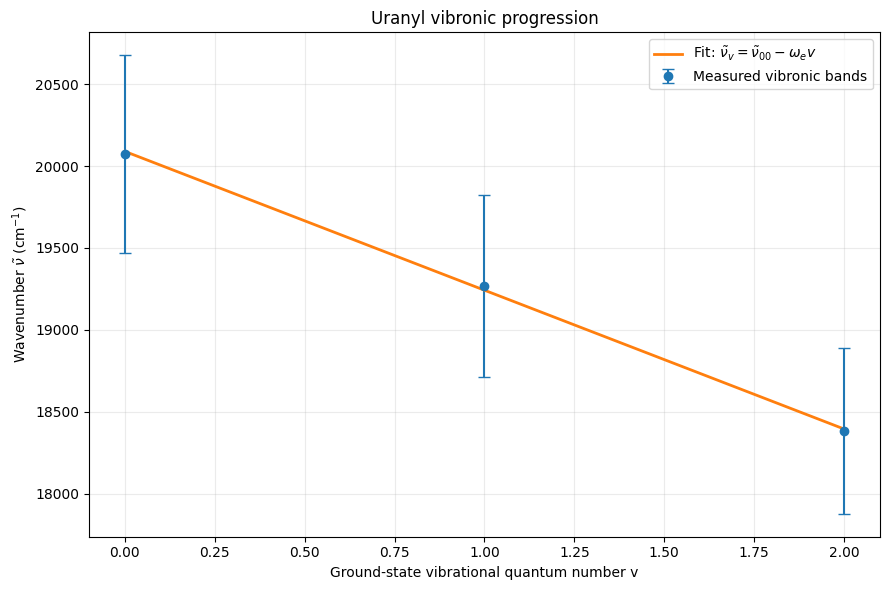


================ ERROR BUDGET ================

Instrumental/readout:
  Drum LC = 0.010 cm
  Drum reading uncertainty = ±0.00500 cm (half least count)
  Galvanometer LC = 0.100 × 100 nA
  Galvanometer reading uncertainty = ±0.05000 × 100 nA (half least count)

Calibration (decaying exponential, lambda = C + A*exp(-(D - D0)/tau)):
  A = +257.2292 nm, tau = 1.9586 cm, C = +369.5895 nm, D0 = 12.8700 cm
  Exponential-fit training RMSE = 9.5904 nm
  LOOCV calibration uncertainty = 14.9624 nm

Statistical/internal consistency:
  Adjacent spacing SEM = 41.7375 cm^-1
  Weighted-fit uncertainty in omega_e = 391.5813 cm^-1

Systematic effects that cannot be reliably assigned numerical values
from this single scan:
  • mechanical backlash
  • slit-width / instrumental spectral resolution
  • PMT gain drift
  • lamp intensity drift
  • background / stray light
  • unresolved Hg doublets
  • incorrect peak assignment
  • calibration-model inadequacy (exponential form assumed)

Do not combine these

In [19]:

# ==============================================================
# 14. LOCAL PEAK-CENTER FIT
# ==============================================================

def local_quadratic_peak(D, I, D_guess, half_width=0.025, verbose=True):
    """
    Fit:
        I(D) = a(D-D0)^2 + b(D-D0) + c

    and calculate the maximum:
        D_peak = D0 - b/(2a)

    The covariance matrix gives a statistical uncertainty on the fitted
    peak center, conditional on the local quadratic model.
    """
    mask = np.abs(D - D_guess) <= half_width

    if mask.sum() < 5:
        raise ValueError(
            f"Not enough data around D={D_guess:.4f} cm "
            "for a peak-center fit."
        )

    x = D[mask]
    y = I[mask]

    x0 = np.mean(x)
    u = x - x0

    def quad(u, a, b, c):
        return a*u*u + b*u + c

    popt, pcov = curve_fit(
        quad,
        u,
        y,
        p0=(-1.0, 0.0, np.max(y)),
        maxfev=10000,
    )

    a, b, c = popt

    if a >= 0:
        raise ValueError(
            f"Peak at D={D_guess:.4f} cm does not have a concave-down "
            "local quadratic fit."
        )

    u_peak = -b / (2.0 * a)
    D_peak = x0 + u_peak

    # Gradient of -b/(2a) wrt [a,b,c]  (delta-method / linearized propagation)
    grad = np.array([
        b/(2.0*a*a),
        -1.0/(2.0*a),
        0.0
    ])

    variance = float(grad @ pcov @ grad)
    u_D_fit = np.sqrt(max(variance, 0.0))

    if verbose:
        print(f"\n    -- local quadratic fit trace around D_guess={D_guess:.4f} cm --")
        print(f"       points used: n={int(mask.sum())}, window=+/-{half_width} cm, x0(mean)={x0:.5f} cm")
        print(f"       fitted (a,b,c) = ({a:.4f}, {b:.4f}, {c:.4f})")
        print(f"       pcov(a,b,c) =\n{np.array2string(pcov, precision=4)}")
        print(f"       u_peak = -b/(2a) = {u_peak:.6f} cm  ->  D_peak = x0+u_peak = {D_peak:.6f} cm")
        print(f"       gradient dD_peak/d(a,b,c) = ({grad[0]:.5f}, {grad[1]:.5f}, {grad[2]:.5f})")
        print(f"       Var(D_peak) = grad . pcov . grad^T = {variance:.3e} cm^2")
        print(f"       u_D_fit = sqrt(Var) = {u_D_fit:.6f} cm")

    return D_peak, u_D_fit


# ==============================================================
# 15. BAND EXTRACTION + WAVENUMBER UNCERTAINTY
# ==============================================================

if not FLUORESCENCE_BAND_DRUMS:
    print("\n================ FINAL BAND ANALYSIS ================")
    print(
        "No final fluorescence-band positions were entered.\n"
        "Add verified values to FLUORESCENCE_BAND_DRUMS and rerun."
    )
    raise SystemExit


def wavelength_to_wavenumber(lambda_nm):
    return 1.0e7 / np.asarray(lambda_nm)


def u_wavenumber_from_u_lambda(lambda_nm, u_lambda_nm):
    return (
        1.0e7 / lambda_nm**2
    ) * u_lambda_nm


band_results = []

for D_guess in FLUORESCENCE_BAND_DRUMS:

    # First determine the peak center in drum space from the raw data.
    # Only then convert that peak center to wavelength.

    D_peak, u_D_fit = local_quadratic_peak(
    fl_D,
    fl_I,
    D_guess,
    half_width=0.025
    )

    # The exponential fit is only validated inside the Hg calibration range
    # (its LOOCV error is characterised there), so never extrapolate.
    if not (Dcal.min() <= D_peak <= Dcal.max()):
        raise ValueError(
            f"Peak centre D={D_peak:.5f} cm lies outside the Hg calibration "
            f"range [{Dcal.min():.3f}, {Dcal.max():.3f}] cm."
        )

    lambda_peak = float(calib(D_peak))

    slope = float(calib.derivative(D_peak))

    # Combine the half-least-count reading uncertainty and the fitted
    # peak-center uncertainty as independent contributions.
    u_D_total = np.sqrt(
        U_DRUM**2 +
        u_D_fit**2
    )

    u_lambda_reading = abs(slope) * u_D_total

    # Combine with empirical calibration uncertainty.
    u_lambda = np.sqrt(
        u_lambda_reading**2 +
        sigma_cal_nm**2
    )

    nubar = float(wavelength_to_wavenumber(lambda_peak))
    u_nubar = float(
        u_wavenumber_from_u_lambda(lambda_peak, u_lambda)
    )

    print(f"    band @ D_guess={D_guess:.4f} cm  -- full uncertainty chain --")
    print(f"       D_peak={D_peak:.5f} cm, exponential-fit slope dλ/dD={slope:.4f} nm/cm")
    print(
        f"       u_D_total  = sqrt(U_DRUM^2 + u_D_fit^2) "
        f"= sqrt({U_DRUM:.5f}^2 + {u_D_fit:.5f}^2) = {u_D_total:.5f} cm"
    )
    print(
        f"       u_lambda,reading = |slope| * u_D_total "
        f"= {abs(slope):.4f} * {u_D_total:.5f} = {u_lambda_reading:.5f} nm"
    )
    print(
        f"       u_lambda   = sqrt(u_lambda,reading^2 + sigma_cal_nm^2) "
        f"= sqrt({u_lambda_reading:.5f}^2 + {sigma_cal_nm:.4f}^2) = {u_lambda:.4f} nm"
    )
    print(f"       lambda_peak = {lambda_peak:.4f} nm  ->  nu_bar = 1e7/lambda = {nubar:.3f} cm^-1")
    print(
        f"       u_nu_bar   = (1e7/lambda^2) * u_lambda "
        f"= ({1.0e7/lambda_peak**2:.6f}) * {u_lambda:.4f} = {u_nubar:.3f} cm^-1\n"
    )

    band_results.append({
        "D_cm": D_peak,
        "u_D_cm": u_D_total,
        "lambda_nm": lambda_peak,
        "u_lambda_nm": u_lambda,
        "wavenumber_cm-1": nubar,
        "u_wavenumber_cm-1": u_nubar,
    })


# Highest-energy/shortest-wavelength member is assigned v=0.
band_results.sort(key=lambda r: r["lambda_nm"])

for v, r in enumerate(band_results):
    r["v"] = v


print("\n================ FINAL FLUORESCENCE BANDS ================")

for r in band_results:
    print(
        f"v={r['v']:d}  "
        f"D={r['D_cm']:.5f}±{r['u_D_cm']:.5f} cm  "
        f"lambda={r['lambda_nm']:.3f}±{r['u_lambda_nm']:.3f} nm  "
        f"nu_bar={r['wavenumber_cm-1']:.2f}"
        f"±{r['u_wavenumber_cm-1']:.2f} cm^-1"
    )


# ==============================================================
# 16. ADJACENT VIBRATIONAL SPACINGS
# ==============================================================

nu = np.array([r["wavenumber_cm-1"] for r in band_results])
u_nu = np.array([r["u_wavenumber_cm-1"] for r in band_results])

if len(nu) < 3:
    raise ValueError(
        "At least three bands are required for a useful vibronic "
        "progression analysis."
    )

spacing = nu[:-1] - nu[1:]

# Propagate uncertainty for each adjacent difference.
u_spacing = np.sqrt(
    u_nu[:-1]**2 +
    u_nu[1:]**2
)

mean_spacing = np.mean(spacing)
u_spacing_sem = (
    np.std(spacing, ddof=1) / np.sqrt(len(spacing))
    if len(spacing) > 1 else np.nan
)

print("\n================ ADJACENT SPACINGS ================")

for i, (s, us) in enumerate(zip(spacing, u_spacing)):
    print(
        f"(0-{i}) -> (0-{i+1}): "
        f"{s:.2f} ± {us:.2f} cm^-1"
    )

print(
    f"\nMean adjacent spacing = "
    f"{mean_spacing:.2f} cm^-1"
)

print(
    f"SEM from band-to-band spread = "
    f"{u_spacing_sem:.2f} cm^-1"
)


# ==============================================================
# 17. WEIGHTED LINEAR REGRESSION OF VIBRONIC PROGRESSION
# ==============================================================

"""
Fit:
    nu_bar(v) = nu_00 - omega_e*v

This simultaneously uses all measured bands and is preferable to estimating
omega_e from only one pair.

Important:
The spacing scatter and the formal regression uncertainty describe
different things:

  - regression uncertainty: propagation of the estimated wavelength errors;
  - spacing scatter: empirical reproducibility/internal consistency of the
    observed progression.

Report both where appropriate.
"""

v = np.array([r["v"] for r in band_results], dtype=float)


def vibronic_line(v, nu00, omega):
    return nu00 - omega*v


weights = 1.0 / u_nu**2

print("\n---- Weighted least-squares trace: nu_bar(v) = nu_00 - omega_e * v ----")
print("Each band is weighted by w_i = 1/sigma_i^2 (absolute_sigma=True):")
for vi, nui, ui, wi in zip(v, nu, u_nu, weights):
    print(f"    v={int(vi)}: nu={nui:9.2f} cm^-1, sigma={ui:8.2f} cm^-1, w=1/sigma^2={wi:.4e}")

popt, pcov = curve_fit(
    vibronic_line,
    v,
    nu,
    sigma=u_nu,
    absolute_sigma=True,
    p0=[nu[0], mean_spacing],
)

nu00_fit = float(popt[0])
omega_e_fit = float(popt[1])

u_nu00_fit = float(np.sqrt(pcov[0, 0]))
u_omega_fit = float(np.sqrt(pcov[1, 1]))

print(f"\nFitted parameter covariance matrix (cm^-1)^2, order [nu_00, omega_e]:")
print(np.array2string(pcov, precision=2, suppress_small=False))
print(
    f"Correlation coefficient rho(nu_00, omega_e) = "
    f"pcov[0,1] / sqrt(pcov[0,0]*pcov[1,1]) = "
    f"{pcov[0,1] / np.sqrt(pcov[0,0]*pcov[1,1]):+.4f}"
)
print(
    "(A large positive correlation here means the fit cannot fully separate\n"
    " an offset in nu_00 from a change in slope omega_e with only 3 points --\n"
    " see the write-up for what this implies about interpreting u_nu00 and\n"
    " u_omega_e in isolation.)"
)

prediction = vibronic_line(v, *popt)
residual = nu - prediction

print("\nFit residuals (measured - predicted):")
for vi, nui, pi, ri in zip(v, nu, prediction, residual):
    print(f"    v={int(vi)}: measured={nui:9.2f}, predicted={pi:9.2f}, residual={ri:+9.2f} cm^-1")

ss_res = np.sum(residual**2)
ss_tot = np.sum((nu - np.mean(nu))**2)

R2 = (
    1 - ss_res/ss_tot
    if ss_tot != 0
    else np.nan
)

print(f"\nSS_res = sum(residual^2) = {ss_res:.3f}")
print(f"SS_tot = sum((nu - mean(nu))^2) = {ss_tot:.3f}")
print(f"R^2 = 1 - SS_res/SS_tot = {R2:.6f}")

print("\n================ VIBRONIC REGRESSION ================")
print(
    f"nu_00 = {nu00_fit:.2f} ± {u_nu00_fit:.2f} cm^-1"
)
print(
    f"omega_e = {omega_e_fit:.2f} ± {u_omega_fit:.2f} cm^-1"
)
print(f"R^2 = {R2:.6f}")


# ==============================================================
# 18. 0-0 WAVELENGTH + FIRST ELECTRONIC EXCITATION ENERGY
# ==============================================================

"""
The 0-0 band gives the origin transition in the simple model because v=0:
    nu_(0-0) = nu_00

Energy:
    E_00 = h c nu_00

In eV:
    E[eV] = 1.239841984e-4 * nu[cm^-1]
"""

lambda00 = band_results[0]["lambda_nm"]
u_lambda00 = band_results[0]["u_lambda_nm"]

E00_eV = 1.239841984e-4 * nu00_fit
u_E00_eV = 1.239841984e-4 * u_nu00_fit

print("\n================ 0-0 TRANSITION ================")
print(
    f"lambda_00 = "
    f"{lambda00:.3f} ± {u_lambda00:.3f} nm"
)
print(
    f"nu_00 = "
    f"{nu00_fit:.2f} ± {u_nu00_fit:.2f} cm^-1"
)
print(
    f"E_00 = "
    f"{E00_eV:.6f} ± {u_E00_eV:.6f} eV"
)


# ==============================================================
# 19. FORCE CONSTANT
# ==============================================================

"""
Harmonic symmetric-stretch relation:

    omega_e = [1/(2*pi*c)] sqrt(f/m_O)

where:
    omega_e is in cm^-1
    c is in cm/s
    m_O is in grams

Therefore:

    f = m_O (2*pi*c*omega_e)^2

For oxygen:
    m_O = 15.999 amu

and

    f[dyn/cm]
      = m_O[amu] * m_u[g] * (2*pi*c*omega_e)^2

This makes:
    f ∝ omega_e^2

and hence:

    u_f/f = 2 u_omega/omega

NOTE:
A previous analysis draft incorrectly contained a square-root dependence
on omega_e. That is inconsistent with the harmonic-oscillator equation
above and is corrected here.
"""

AMU_TO_G = 1.66053906660e-24
C_CGS = 2.99792458e10

mO_g = 15.999 * AMU_TO_G
angfreq_term = 2.0*np.pi*C_CGS*omega_e_fit  # 2*pi*c*omega_e, units s^-1

force_dyne_cm = (
    mO_g *
    (angfreq_term)**2
)

rel_u_omega = abs(u_omega_fit / omega_e_fit)

u_force_dyne_cm = (
    force_dyne_cm *
    2.0 *
    rel_u_omega
)

# 1 dyne/cm = 1e-3 N/m
force_N_m = force_dyne_cm * 1e-3
u_force_N_m = u_force_dyne_cm * 1e-3

print("\n---- Force-constant propagation trace: f = m_O (2*pi*c*omega_e)^2 ----")
print(f"m_O = 15.999 amu * {AMU_TO_G:.6e} g/amu = {mO_g:.5e} g")
print(f"2*pi*c*omega_e = 2*pi * {C_CGS:.6e} cm/s * {omega_e_fit:.2f} cm^-1 = {angfreq_term:.5e} s^-1")
print(f"f = m_O * (2*pi*c*omega_e)^2 = {mO_g:.5e} * ({angfreq_term:.5e})^2 = {force_dyne_cm:.5e} dyn/cm")
print(
    "\nSince f is proportional to omega_e^2 (power law f = k*omega_e^n, n=2), "
    "relative uncertainty scales as:\n"
    "   u_f/f = n * |u_omega_e/omega_e| = 2 * |u_omega_e/omega_e|"
)
print(f"   |u_omega_e/omega_e| = |{u_omega_fit:.2f}/{omega_e_fit:.2f}| = {rel_u_omega:.4f}  ({rel_u_omega*100:.1f}% relative)")
print(f"   u_f/f = 2 * {rel_u_omega:.4f} = {2.0*rel_u_omega:.4f}  ({2.0*rel_u_omega*100:.1f}% relative)")
print(f"   u_f = {2.0*rel_u_omega:.4f} * {force_dyne_cm:.5e} = {u_force_dyne_cm:.3e} dyn/cm")
if rel_u_omega > 0.5:
    print(
        "\n   WARNING: relative uncertainty in omega_e exceeds 50% "
        "(here {:.0f}%), so f is only an order-of-magnitude estimate,\n"
        "   not a precisely determined force constant -- see write-up "
        "Section 10.3.".format(rel_u_omega*100)
    )

print("\n================ FORCE CONSTANT ================")
print(
    f"f = ({force_dyne_cm:.5e} ± "
    f"{u_force_dyne_cm:.2e}) dyn/cm"
)
print(
    f"f = ({force_N_m:.5e} ± "
    f"{u_force_N_m:.2e}) N/m"
)


# ==============================================================
# 20. VIBRONIC PROGRESSION PLOT
# ==============================================================

plt.figure(figsize=(9, 6))

plt.errorbar(
    v,
    nu,
    yerr=u_nu,
    fmt="o",
    capsize=4,
    label="Measured vibronic bands"
)

vv = np.linspace(v.min(), v.max(), 200)

plt.plot(
    vv,
    vibronic_line(vv, *popt),
    lw=2,
    label=r"Fit: $\tilde{\nu}_v=\tilde{\nu}_{00}-\omega_e v$"
)

plt.xlabel("Ground-state vibrational quantum number v")
plt.ylabel(r"Wavenumber $\tilde{\nu}$ (cm$^{-1}$)")
plt.title("Uranyl vibronic progression")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.savefig("07_vibronic_progression.png", dpi=300)
plt.show()


# ==============================================================
# 21. ERROR BUDGET
# ==============================================================

print("\n================ ERROR BUDGET ================")

print("\nInstrumental/readout:")
print(
    f"  Drum LC = {DRUM_LC_CM:.3f} cm"
)
print(
    f"  Drum reading uncertainty = ±{U_DRUM:.5f} cm (half least count)"
)
print(
    f"  Galvanometer LC = {GALV_LC_100nA:.3f} × 100 nA"
)
print(
    f"  Galvanometer reading uncertainty = ±{U_GALV:.5f} × 100 nA (half least count)"
)

print("\nCalibration (decaying exponential, lambda = C + A*exp(-(D - D0)/tau)):")
print(
    f"  A = {exp_params['A']:+.4f} nm, tau = {exp_params['tau']:.4f} cm, "
    f"C = {exp_params['C']:+.4f} nm, D0 = {exp_params['D0']:.4f} cm"
)
print(
    f"  Exponential-fit training RMSE = {rmse_train:.4f} nm"
)
print(
    f"  LOOCV calibration uncertainty = {sigma_cal_nm:.4f} nm"
)

print("\nStatistical/internal consistency:")
print(
    f"  Adjacent spacing SEM = {u_spacing_sem:.4f} cm^-1"
)
print(
    f"  Weighted-fit uncertainty in omega_e = {u_omega_fit:.4f} cm^-1"
)

print("\nSystematic effects that cannot be reliably assigned numerical values")
print("from this single scan:")
print("  • mechanical backlash")
print("  • slit-width / instrumental spectral resolution")
print("  • PMT gain drift")
print("  • lamp intensity drift")
print("  • background / stray light")
print("  • unresolved Hg doublets")
print("  • incorrect peak assignment")
print("  • calibration-model inadequacy (exponential form assumed)")

print(
    "\nDo not combine these unquantified systematic effects into a numerical "
    "± error unless they were experimentally measured (for example by "
    "repeated scans, reverse-direction scans, independent calibration, "
    "background measurements, or resolution measurements)."
)


# ==============================================================
# 22. SAVE MACHINE-READABLE RESULTS
# ==============================================================

results = pd.DataFrame(band_results)

results_file = "uranyl_vibronic_band_results.csv"
results.to_csv(results_file, index=False)

print(
    f"\nBand results saved to:\n{results_file}"
)

print("\n================ ANALYSIS COMPLETE ================")